In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## load data

In [ ]:
from pathlib import Path

file_path = Path(r"c:\Users\nada\Desktop\SeoulBikeData.csv")
df = pd.read_csv(file_path, encoding="cp1252")

In [3]:
df.shape

(8760, 14)

In [4]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   object 
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   object 
 12  Holiday                    8760 non-null   object 
 13  Functioning Day            8760 non-null   objec

In [6]:
df.describe(include='all')

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
count,8760,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760,8760,8760
unique,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,2,2
top,01/12/2017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Spring,No Holiday,Yes
freq,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2208,8328,8465
mean,NaN,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068,NaN,NaN,NaN
std,NaN,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746,NaN,NaN,NaN
min,NaN,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000,NaN,NaN,NaN
50%,NaN,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000,NaN,NaN,NaN
75%,NaN,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000,NaN,NaN,NaN


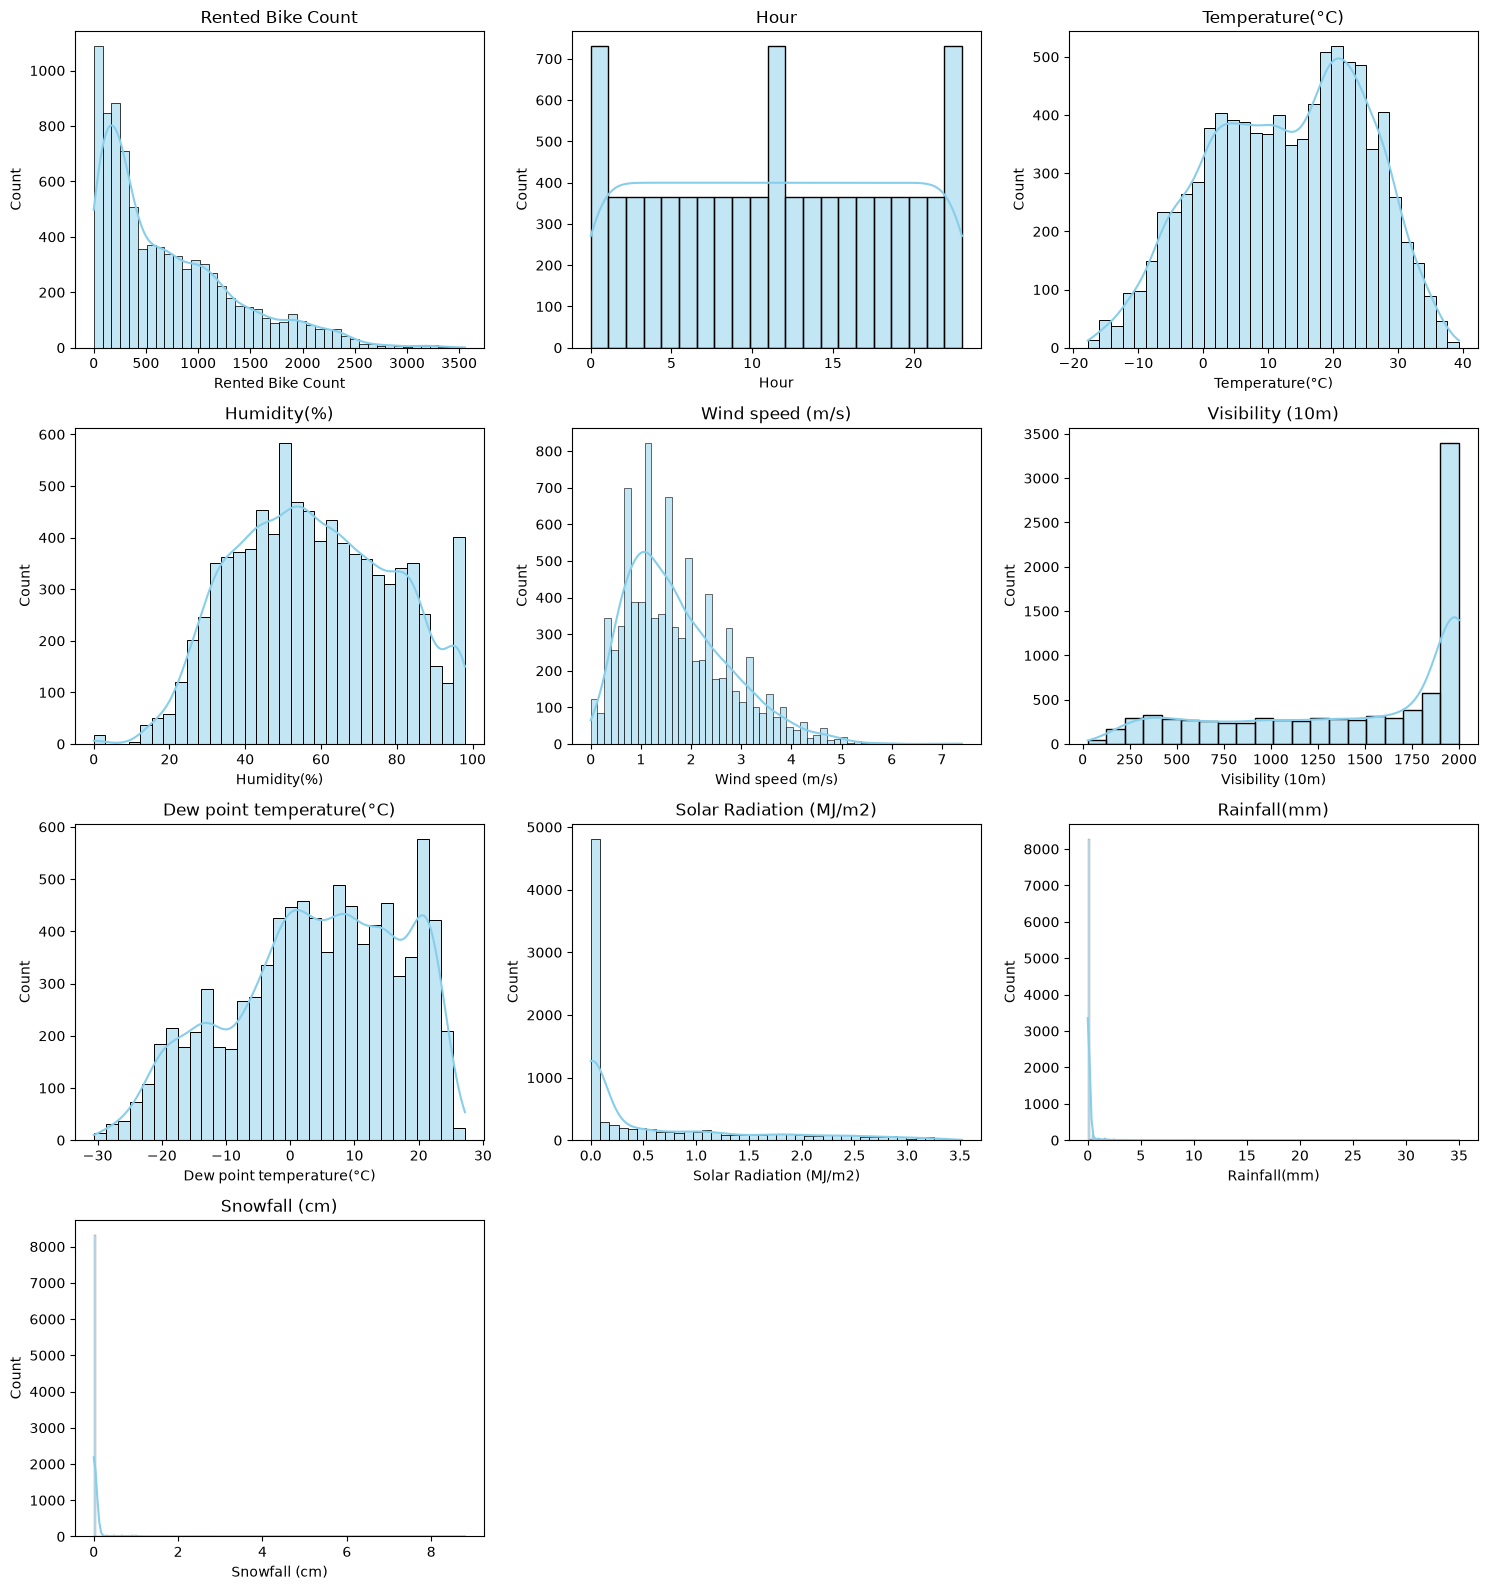

In [7]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numerical_cols = df.select_dtypes(include='number').columns

n_cols = 3  # Number of plots per row
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(col)

# Delete empty axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

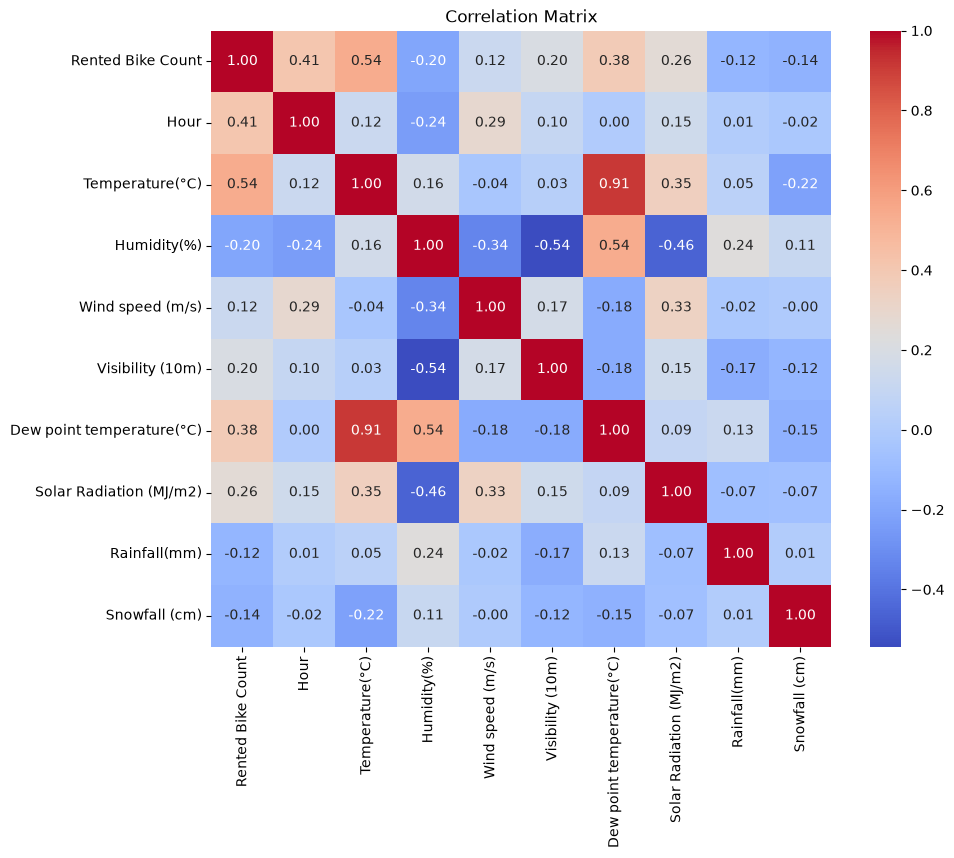

In [8]:
# Correlation matrix
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [4]:
df.drop(columns=['Solar Radiation (MJ/m2)','Rainfall(mm)', 'Snowfall (cm)'], inplace=True)

# skewness of the target data

In [10]:
# it is > 1 .. which means the data is positively skewed

df['Rented Bike Count'].skew()

np.float64(1.1534281773679014)

# Visualize it 

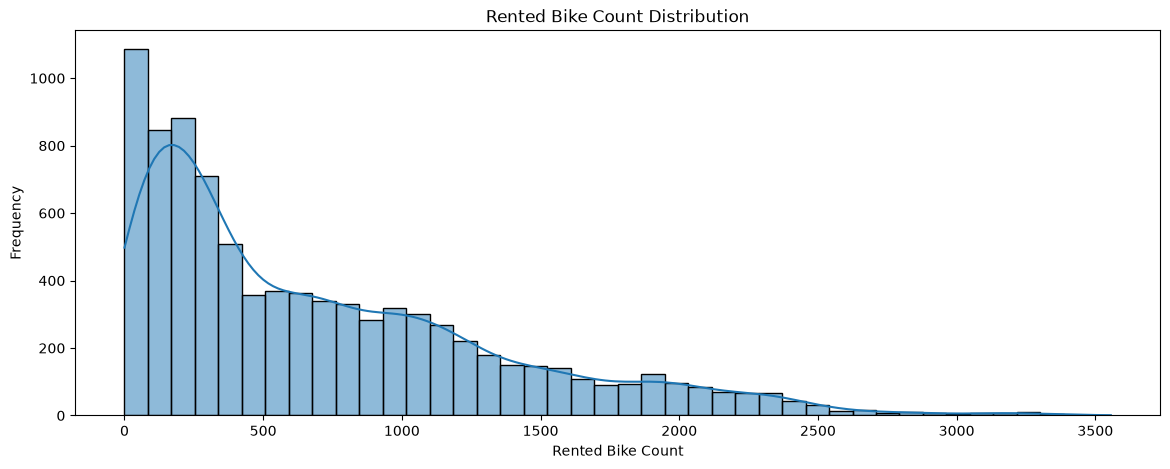

In [ ]:
# I may use log transformation
# I will compare and see if the model performance improves after log transformation or not

plt.figure(figsize=(14, 5))
sns.histplot(df["Rented Bike Count"], kde=True)

plt.title("Rented Bike Count Distribution")
plt.xlabel("Rented Bike Count")
plt.ylabel("Frequency")
plt.show()

In [5]:
# Convert "Date" feature to datetime and sort the dataset by date

df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df = df.sort_values(by=["Date"]).reset_index(drop=True)

In [6]:
# one-hot encode the "Seasons" feature
df = pd.get_dummies(df, columns=['Seasons'], dtype=int)
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Holiday,Functioning Day,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,No Holiday,Yes,0,0,0,1
1,2017-12-01,323,23,-1.3,84,1.0,1265,-3.6,No Holiday,Yes,0,0,0,1
2,2017-12-01,398,22,-0.9,83,1.5,1380,-3.4,No Holiday,Yes,0,0,0,1
3,2017-12-01,405,21,-0.8,81,0.8,1687,-3.6,No Holiday,Yes,0,0,0,1
4,2017-12-01,426,20,-0.3,79,1.5,1913,-3.5,No Holiday,Yes,0,0,0,1


In [14]:
print(df['Holiday'].unique())
print(df['Functioning Day'].unique())

['No Holiday' 'Holiday']
['Yes' 'No']


- Binary Encoding

In [7]:
# Two category features

binary_features = ['Holiday','Functioning Day']

# Map the values to 0 and 1
df[binary_features] = df[binary_features].replace({ 
'No Holiday': 0 , 'Holiday': 1,
'No': 0 , 'Yes': 1
})

# convert the binary columns to integer type
df[binary_features] = df[binary_features].astype(int)

C:\Users\nada\AppData\Local\Temp\ipykernel_11640\223207712.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[binary_features] = df[binary_features].replace({


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       8760 non-null   datetime64[ns]
 1   Rented Bike Count          8760 non-null   int64         
 2   Hour                       8760 non-null   int64         
 3   Temperature(°C)            8760 non-null   float64       
 4   Humidity(%)                8760 non-null   int64         
 5   Wind speed (m/s)           8760 non-null   float64       
 6   Visibility (10m)           8760 non-null   int64         
 7   Dew point temperature(°C)  8760 non-null   float64       
 8   Holiday                    8760 non-null   int64         
 9   Functioning Day            8760 non-null   int64         
 10  Seasons_Autumn             8760 non-null   int64         
 11  Seasons_Spring             8760 non-null   int64         
 12  Season

## Make the model learn the patterns of Time-Series 
- Extracte features from "Date" column 
- lag
- rolling
- (Lag uses a single previous observation as a feature , Rolling computes a statistic (such as the mean, sum, or standard deviation) over a window of previous observations )

Extract features from 'Date' column

In [ ]:
df["Day"] = df["Date"].dt.day
# I already have Holiday column, so I think there is no need to add 'day of week' column 
df["Week_of_Year"] = df["Date"].dt.isocalendar().week
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

# cyclical features so that 23 and 0 are treated as adjacent.
df['Hour_Sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
df['Hour_Cos'] = np.cos(2 * np.pi * df['Hour'] / 24)


In [9]:
df.drop(columns=["Date"], inplace=True)

In [19]:
df.head()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Holiday,Functioning Day,Seasons_Autumn,Seasons_Spring,Seasons_Summer,Seasons_Winter,Day,Week_of_Year,Month,Year,Hour_Sin,Hour_Cos
0,254,0,-5.2,37,2.2,2000,-17.6,0,1,0,0,0,1,1,48,12,2017,0.000000,1.000000
1,323,23,-1.3,84,1.0,1265,-3.6,0,1,0,0,0,1,1,48,12,2017,-0.258819,0.965926
2,398,22,-0.9,83,1.5,1380,-3.4,0,1,0,0,0,1,1,48,12,2017,-0.500000,0.866025
3,405,21,-0.8,81,0.8,1687,-3.6,0,1,0,0,0,1,1,48,12,2017,-0.707107,0.707107
4,426,20,-0.3,79,1.5,1913,-3.5,0,1,0,0,0,1,1,48,12,2017,-0.866025,0.500000


Lag

In [10]:
# Rented Bike Counts ​​are recorded every hour

df["target_lag_1"] = df["Rented Bike Count"].shift(1)  #Target value 1 hour ago
df["target_lag_3"] = df["Rented Bike Count"].shift(3)  #Target value 3 hours ago
df["target_lag_7"] = df["Rented Bike Count"].shift(7)  
df["target_lag_24"] = df["Rented Bike Count"].shift(24)  

Rolling

In [11]:
#Average for the last 3 hours
df["target_roll_mean_3"] = (
    df["Rented Bike Count"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

#Average for the last 7 hours
df["target_roll_mean_7"] = (
    df["Rented Bike Count"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

# Rolling Standard Deviation (rolling(7).std()) : Uses the standard deviation of the last 7 hours
df["target_roll_std_7"]= (
    df["Rented Bike Count"]
    .shift(1)
    .rolling(window=7)
    .std()
)

# Minimum / Maximum
df["target_roll_min_7"] = (
    df["Rented Bike Count"]
    .shift(1)
    .rolling(window=7)
    .min()
)

df["target_roll_max_7"] = (
    df["Rented Bike Count"]
    .shift(1)
    .rolling(window=7)
    .max()
)


# Drop rows that now become with NaN
df = df.dropna()


df.head()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Holiday,Functioning Day,Seasons_Autumn,...,Hour_Cos,target_lag_1,target_lag_3,target_lag_7,target_lag_24,target_roll_mean_3,target_roll_mean_7,target_roll_std_7,target_roll_min_7,target_roll_max_7
24,611,14,7.3,35,1.3,1955,-7.1,0,1,0,...,-8.660254e-01,360.0,173.0,181.0,254.0,245.666667,171.857143,95.476749,78.0,360.0
25,589,15,7.6,41,2.3,1953,-4.8,0,1,0,...,-7.071068e-01,611.0,204.0,100.0,323.0,391.666667,233.285714,191.938978,78.0,611.0
26,618,16,6.4,48,2.6,1945,-3.8,0,1,0,...,-5.000000e-01,589.0,360.0,78.0,398.0,520.000000,303.142857,221.980051,78.0,611.0
27,572,17,6.0,51,2.5,1891,-3.3,0,1,0,...,-2.588190e-01,618.0,611.0,107.0,405.0,606.000000,380.285714,224.514078,107.0,618.0
28,489,18,5.5,53,1.5,1697,-3.3,0,1,0,...,-1.836970e-16,572.0,589.0,173.0,426.0,593.000000,446.714286,197.323520,173.0,618.0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8736 entries, 24 to 8759
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Rented Bike Count          8736 non-null   int64  
 1   Hour                       8736 non-null   int64  
 2   Temperature(°C)            8736 non-null   float64
 3   Humidity(%)                8736 non-null   int64  
 4   Wind speed (m/s)           8736 non-null   float64
 5   Visibility (10m)           8736 non-null   int64  
 6   Dew point temperature(°C)  8736 non-null   float64
 7   Holiday                    8736 non-null   int64  
 8   Functioning Day            8736 non-null   int64  
 9   Seasons_Autumn             8736 non-null   int64  
 10  Seasons_Spring             8736 non-null   int64  
 11  Seasons_Summer             8736 non-null   int64  
 12  Seasons_Winter             8736 non-null   int64  
 13  Day                        8736 non-null   int32  
 

## save processed data

In [14]:
from pathlib import Path

path = Path(r"c:\Users\nada\Desktop\SeoulBikeData_processed.csv")
df.to_csv(path, index=False)

- # Visualize the data distribution (after feature engineering)

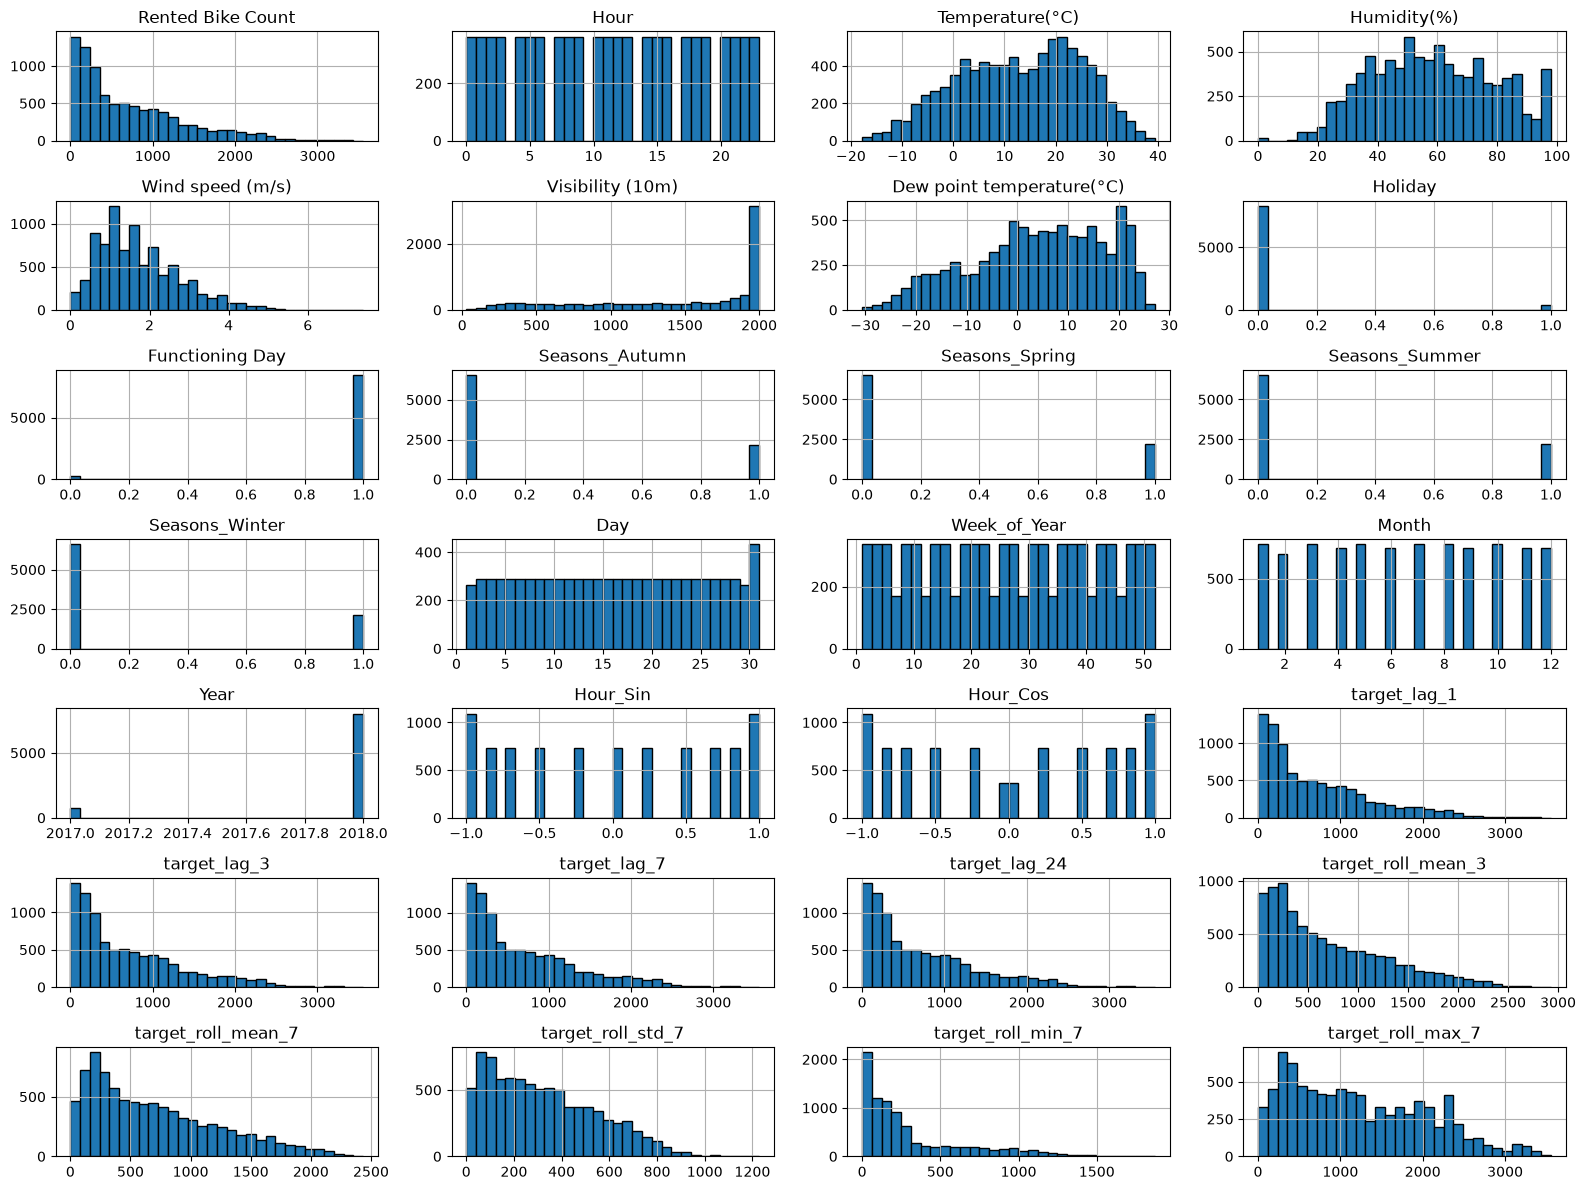

In [23]:
import matplotlib.pyplot as plt

df.hist(
    figsize=(16, 12),
    bins=30,
    layout=(-1, 4),   # 4 plots per row
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [24]:
df.describe(include='all')

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Holiday,Functioning Day,Seasons_Autumn,...,Hour_Cos,target_lag_1,target_lag_3,target_lag_7,target_lag_24,target_roll_mean_3,target_roll_mean_7,target_roll_std_7,target_roll_min_7,target_roll_max_7
count,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,...,8.736000e+03,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000,8736.000000
mean,705.445856,11.500000,12.925057,58.260188,1.725424,1435.633700,4.122218,0.049451,0.966232,0.250000,...,-6.100127e-17,705.420215,705.318452,705.206616,704.672276,705.372940,705.292190,324.197557,313.416667,1217.931891
std,645.589607,6.922583,11.932650,20.351073,1.036841,608.510767,13.040735,0.216819,0.180643,0.433037,...,7.071473e-01,645.598879,645.644258,645.721420,645.637129,586.397927,532.561440,224.410126,345.606489,822.117444
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,...,-1.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,43.000000,0.900000,936.000000,-4.600000,0.000000,1.000000,0.000000,...,-7.071068e-01,191.000000,191.000000,190.750000,191.000000,229.250000,255.857143,131.776948,65.000000,499.000000
50%,507.000000,11.500000,13.800000,57.000000,1.500000,1695.000000,5.100000,0.000000,1.000000,0.000000,...,-6.123234e-17,507.000000,506.000000,506.000000,504.000000,538.000000,586.571429,288.630758,178.000000,1083.000000
75%,1066.000000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.825000,0.000000,1.000000,0.250000,...,7.071068e-01,1066.000000,1066.000000,1066.000000,1066.000000,1078.000000,1048.357143,484.282716,437.000000,1887.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,1.000000,1.000000,1.000000,...,1.000000e+00,3556.000000,3556.000000,3556.000000,3556.000000,2928.333333,2435.571429,1228.131701,1872.000000,3556.000000


- correlation

Rented Bike Count            1.000000
target_lag_1                 0.769569
target_roll_mean_3           0.749623
target_roll_mean_7           0.634702
target_roll_max_7            0.614309
target_lag_3                 0.599911
target_roll_std_7            0.566392
target_lag_24                0.546778
Temperature(°C)              0.538313
target_roll_min_7            0.430394
Hour                         0.410565
Dew point temperature(°C)    0.379132
target_lag_7                 0.308978
Seasons_Summer               0.296061
Year                         0.214157
Functioning Day              0.204290
Visibility (10m)             0.200527
Week_of_Year                 0.136622
Month                        0.136125
Wind speed (m/s)             0.120995
Seasons_Autumn               0.102092
Seasons_Spring               0.022149
Day                          0.020188
Holiday                     -0.072674
Hour_Cos                    -0.099312
Humidity(%)                 -0.201246
Seasons_Wint

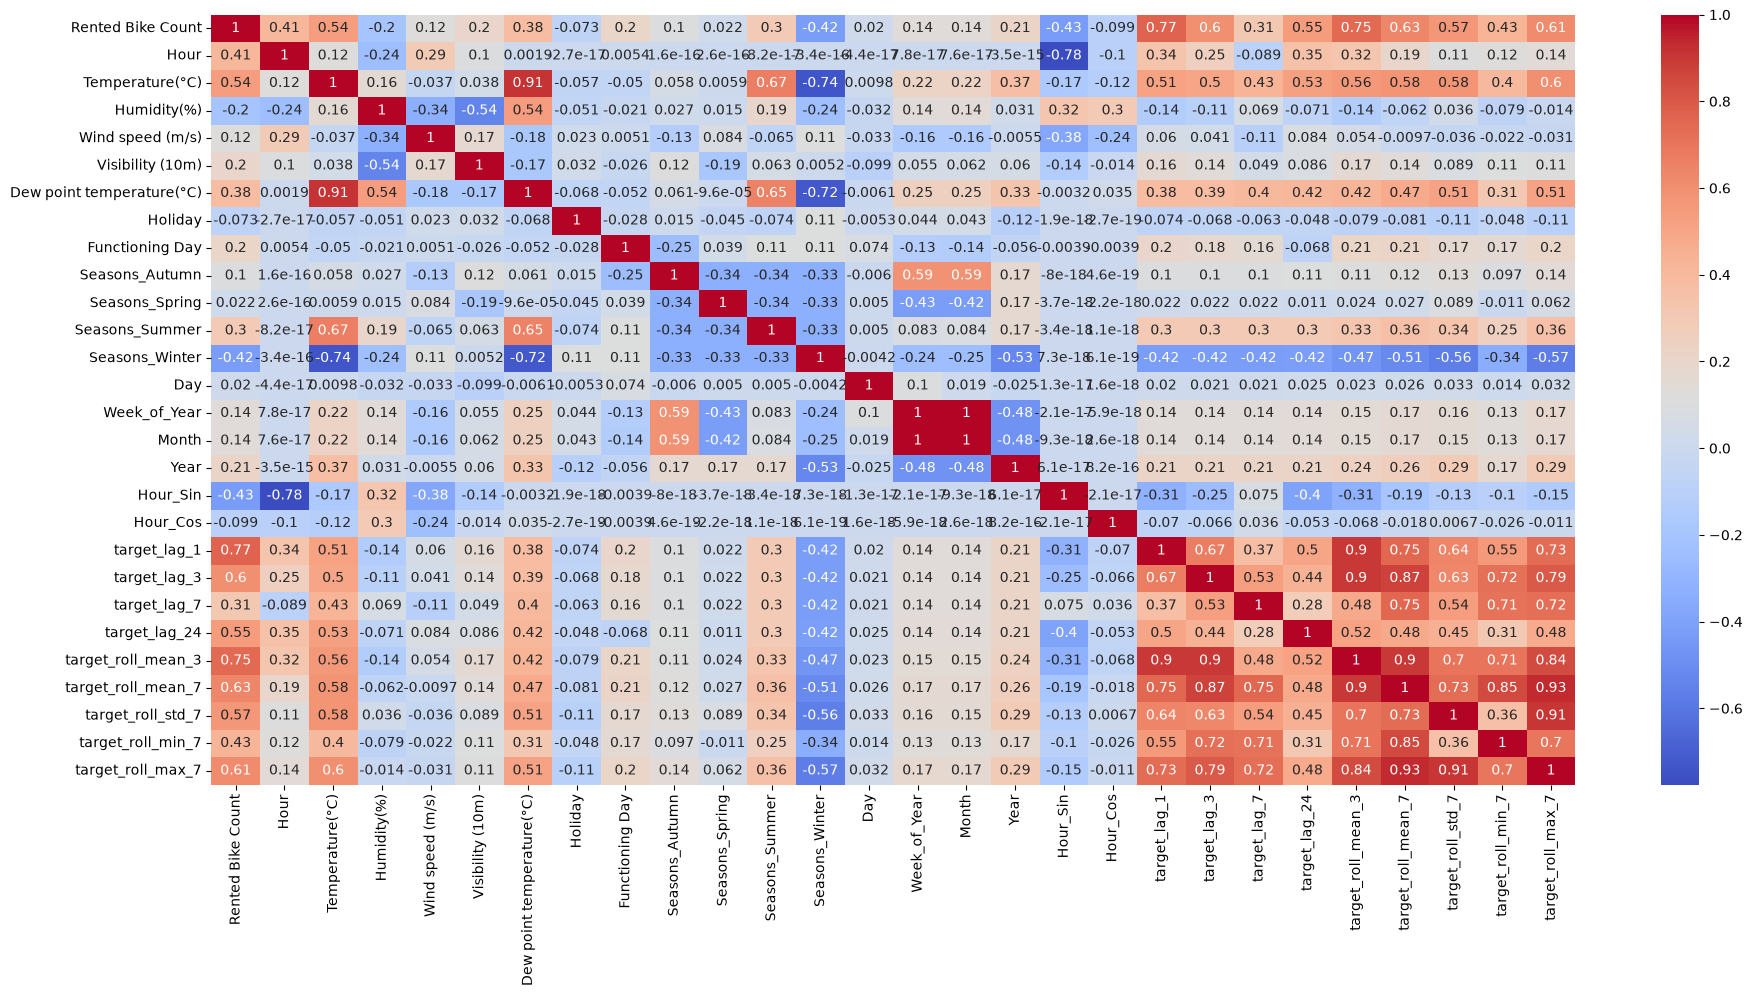

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# correlation matrix
corr_matrix = df.corr()

# show correlation with target
target_corr = corr_matrix["Rented Bike Count"].sort_values(ascending=False)

print(target_corr)

# heatmap
plt.figure(figsize=(22, 10))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.show()

## Time-Based Split ( to prevent data leakage )

In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
import numpy as np

target = "Rented Bike Count"

# Time-based split 
train_size = int(len(df) * 0.80)

train = df.iloc[:train_size]
test = df.iloc[train_size:]

# Separate features and target
X_train = train.drop(columns=[target])
y_train = train[target]

X_test = test.drop(columns=[target])
y_test = test[target]

# Check dataset sizes
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (6988, 27)
Test: (1748, 27)


## Random Forest

MAE : 166.56  / RMSE: 249.52  / R²: 0.8343


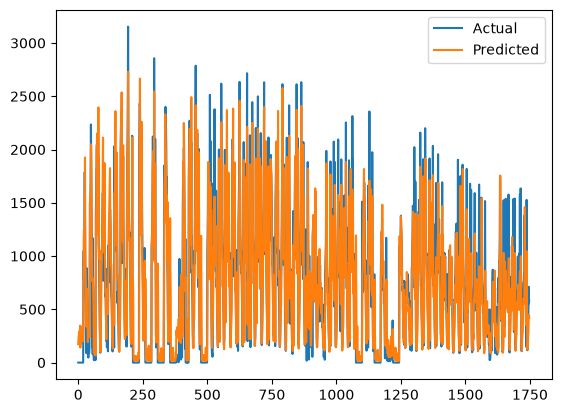

In [27]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=500,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Training
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
mae = mean_absolute_error( y_test, y_pred)
rmse = np.sqrt(mean_squared_error( y_test, y_pred ))
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2)," / RMSE:", round(rmse, 2) ," / R²:", round(r2, 4))

# Actual vs predicted plot
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.legend()
plt.show()

- with log1(target)

MAE : 181.61  / RMSE: 281.21  / R²: 0.7895


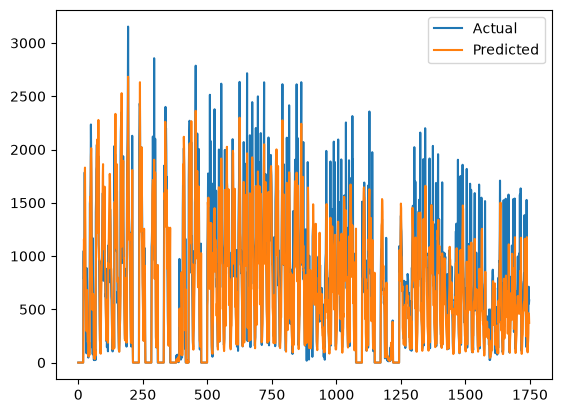

In [28]:
# Log transform target
y_train_log = np.log1p(y_train)

# Training on log target
model.fit(X_train,y_train_log)

# Predict log values
y_pred_log = model.predict(X_test)

# Convert predictions back to original scale
y_pred = np.expm1(y_pred_log)

# Evaluation on original target scale
mae = mean_absolute_error( y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
r2 = r2_score(y_test,y_pred)


print("MAE :", round(mae, 2)," / RMSE:", round(rmse, 2) ," / R²:", round(r2, 4))

# Actual vs predicted plot
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.legend()
plt.show()

## XGBoost

MAE : 141.94  / RMSE: 207.41  / R²: 0.8855


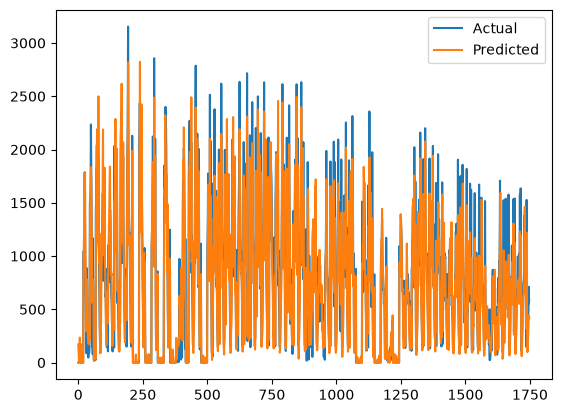

In [ ]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
     objective='reg:squarederror'
)


# Training
model.fit(X_train,y_train)

# Prediction
y_pred = model.predict(X_test)

# to avoid negative predictions, I can clip the predictions to be non-negative
y_pred = np.maximum(y_pred, 0)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))  
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2)," / RMSE:", round(rmse, 2) ," / R²:", round(r2, 4))

# Actual vs predicted plot
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.legend()
plt.show()

- log1(target)

MAE : 160.0  / RMSE: 252.61  / R²: 0.8302


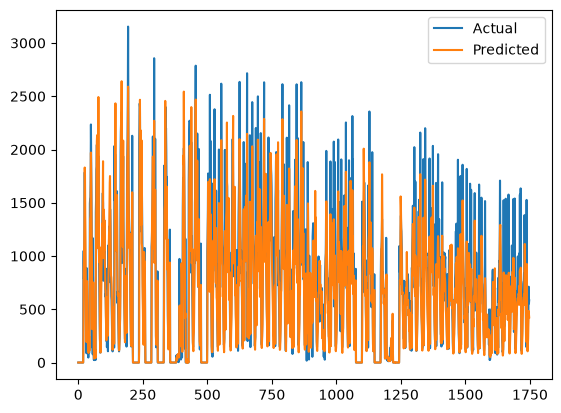

In [30]:
# Apply log1p transformation to target
y_train_log1p = np.log1p(y_train)

# Training on log1p(target)
model.fit(X_train,y_train_log1p)

# Prediction in log1p scale
y_pred_log1p = model.predict(X_test)

# Convert predictions back to original scale
y_pred = np.expm1(y_pred_log1p)

# Evaluation on original target
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt( mean_squared_error(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

print("MAE :", round(mae, 2)," / RMSE:", round(rmse, 2) ," / R²:", round(r2, 4))

# Actual vs predicted plot
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.legend()
plt.show()

## LightGBM

MAE : 142.61  / RMSE: 209.48  / R²: 0.8832


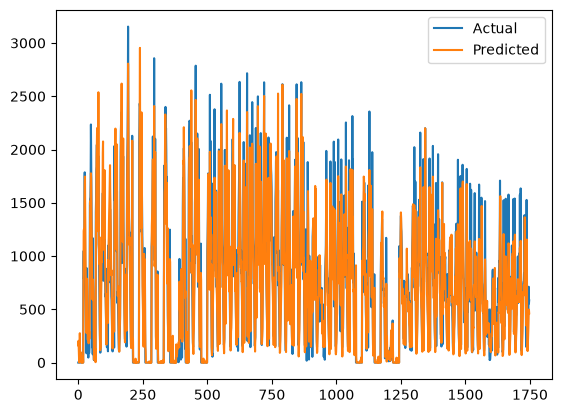

In [ ]:
from lightgbm import LGBMRegressor

model = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
    objective="regression"
)


# Training
model.fit(X_train,y_train)

# Prediction
y_pred = model.predict(X_test)

# to avoid negative predictions, I can clip the predictions to be non-negative
y_pred = np.maximum(y_pred, 0)


# Evaluation
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

print("MAE :", round(mae, 2)," / RMSE:", round(rmse, 2) ," / R²:", round(r2, 4))

# Actual vs predicted plot
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.legend()
plt.show()

- log1p(target)

MAE : 163.02  / RMSE: 249.58  / R²: 0.8342


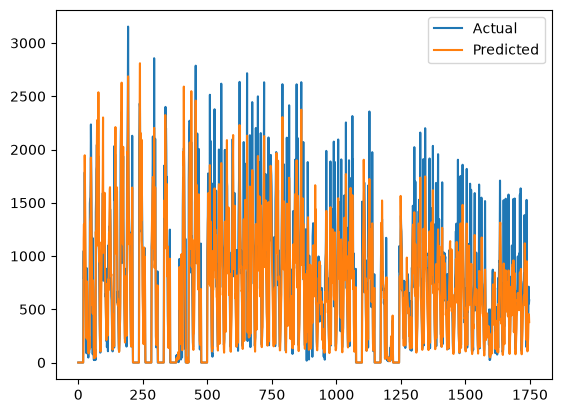

In [32]:
# Log1p transform target
y_train_log1p = np.log1p(y_train)

# Training on log1p(target)
model.fit(X_train, y_train_log1p)

# Prediction in log scale
y_pred_log1p = model.predict(X_test)

# Back to original scale
y_pred = np.expm1(y_pred_log1p)

# Evaluation on original target
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

print("MAE :", round(mae, 2)," / RMSE:", round(rmse, 2) ," / R²:", round(r2, 4))

# Actual vs predicted plot
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.legend()
plt.show()

## - The log1p transformation of the target resulted in worse performance than using the original target itself. Therefore, the final model was trained on the original target values

## - THE CHOSEM MODEL : LIGHTGBM
- cheaper , faster and The performance is very similar

## Optuna : Tunes Hyperparameters

In [36]:
import numpy as np
import optuna
import lightgbm as lgb
from lightgbm import LGBMRegressor, early_stopping
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error

# KFold is not suitable here because it can shuffle the time order , causing data leakage by allowing the model to train on future data
tscv = TimeSeriesSplit(n_splits=5)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "num_leaves": trial.suggest_int("num_leaves", 10, 100),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "random_state": 42,
        "verbose": -1,
        "objective": "regression",
    }


    scores = []

    for fold, (train_idx, valid_idx) in enumerate(tscv.split(X_train)):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[valid_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[valid_idx]

        model = LGBMRegressor(**params)

        # Train on the current fold
        model.fit(
            X_tr,
            y_tr,
            eval_X=X_val,
            eval_y=y_val,
            callbacks=[
                early_stopping(
                    stopping_rounds=100,
                    verbose=False
                )
            ]
        )

        # validation predictions
        pred = model.predict(
            X_val,
            num_iteration=model.best_iteration_
        )

        # validation RMSE
        rmse = np.sqrt(
            mean_squared_error(y_val, pred)
        )

        scores.append(rmse)

        # Report the fold score to Optuna
        trial.report(rmse, step=fold)


    return np.mean(scores)

# Create the Optuna study
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(
        seed=42
    )
)

# Enqueue your existing model parameters
study.enqueue_trial({
    "n_estimators": 500,
    "learning_rate": 0.03,
    "max_depth": 6,
    "num_leaves": 31,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
})

# Run hyperparameter optimization
study.optimize(
    objective,
    n_trials=100,
    show_progress_bar=True
)

print("Best RMSE:", study.best_value)

print("\nBest parameters:")
for k, v in study.best_params.items():
    print(f'"{k}": {v},')

[I 2026-08-08 10:39:37,318] A new study created in memory with name: no-name-0ec1b5ee-d523-485b-89e9-bd48cce499e0
Best trial: 0. Best value: 290.294:   1%|          | 1/100 [00:03<05:56,  3.60s/it]

[I 2026-08-08 10:39:40,914] Trial 0 finished with value: 290.29350002583413 and parameters: {'n_estimators': 500, 'learning_rate': 0.03, 'max_depth': 6, 'num_leaves': 31, 'subsample': 0.8, 'colsample_bytree': 0.8}. Best is trial 0 with value: 290.29350002583413.


Best trial: 0. Best value: 290.294:   2%|▏         | 2/100 [00:05<04:39,  2.85s/it]

[I 2026-08-08 10:39:43,241] Trial 1 finished with value: 292.12172456881547 and parameters: {'n_estimators': 437, 'learning_rate': 0.0862735828664018, 'max_depth': 10, 'num_leaves': 64, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481}. Best is trial 0 with value: 290.29350002583413.


Best trial: 0. Best value: 290.294:   3%|▎         | 3/100 [00:08<04:21,  2.70s/it]

[I 2026-08-08 10:39:45,762] Trial 2 finished with value: 291.52992967667166 and parameters: {'n_estimators': 152, 'learning_rate': 0.06697167353375243, 'max_depth': 9, 'num_leaves': 74, 'subsample': 0.608233797718321, 'colsample_bytree': 0.9879639408647978}. Best is trial 0 with value: 290.29350002583413.


... (190 outputs left out)

Best trial: 56. Best value: 282.939:  99%|█████████▉| 99/100 [04:36<00:01,  1.99s/it]

[I 2026-08-08 10:44:13,389] Trial 98 finished with value: 287.67458069813523 and parameters: {'n_estimators': 601, 'learning_rate': 0.07933536387867667, 'max_depth': 4, 'num_leaves': 27, 'subsample': 0.8493299912481068, 'colsample_bytree': 0.6467469761587111}. Best is trial 56 with value: 282.93861635434604.


Best trial: 56. Best value: 282.939: 100%|██████████| 100/100 [04:37<00:00,  2.78s/it]

[I 2026-08-08 10:44:15,308] Trial 99 finished with value: 286.7044206456986 and parameters: {'n_estimators': 569, 'learning_rate': 0.06418474972763437, 'max_depth': 8, 'num_leaves': 24, 'subsample': 0.7979394284498372, 'colsample_bytree': 0.6095149613728422}. Best is trial 56 with value: 282.93861635434604.
Best RMSE: 282.93861635434604

Best parameters:
"n_estimators": 869,
"learning_rate": 0.07168038938337792,
"max_depth": 5,
"num_leaves": 18,
"subsample": 0.8363920438556471,
"colsample_bytree": 0.6437435164289361,


## Train and Evaluate Optuna Model
- ( To see whether it performs better than the original model )

In [37]:
import mlflow
import mlflow.lightgbm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = LGBMRegressor(**study.best_params, random_state=42)

# Training the model for training only
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# To avoid negative predictions, clip them to zero
y_pred = np.maximum(y_pred, 0)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Feature importance
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})
importance = importance.sort_values(by="Importance", ascending=False)

print(importance)
print("MAE :", round(mae, 2), "/ RMSE:", round(rmse, 2), "/ R²:", round(r2, 4))

                      Feature  Importance
18               target_lag_1         996
1             Temperature(°C)         979
0                        Hour         853
21              target_lag_24         833
22         target_roll_mean_3         815
25          target_roll_min_7         803
26          target_roll_max_7         798
5   Dew point temperature(°C)         765
2                 Humidity(%)         734
24          target_roll_std_7         686
20               target_lag_7         672
19               target_lag_3         654
16                   Hour_Sin         620
17                   Hour_Cos         575
4            Visibility (10m)         560
23         target_roll_mean_7         554
13               Week_of_Year         484
12                        Day         462
3            Wind speed (m/s)         443
7             Functioning Day         144
14                      Month          80
9              Seasons_Spring          44
10             Seasons_Summer     

## optuna model is slightly better .. it is the chosen one

## Train and Evaluate final Model with MLflow (Tracks experiments)

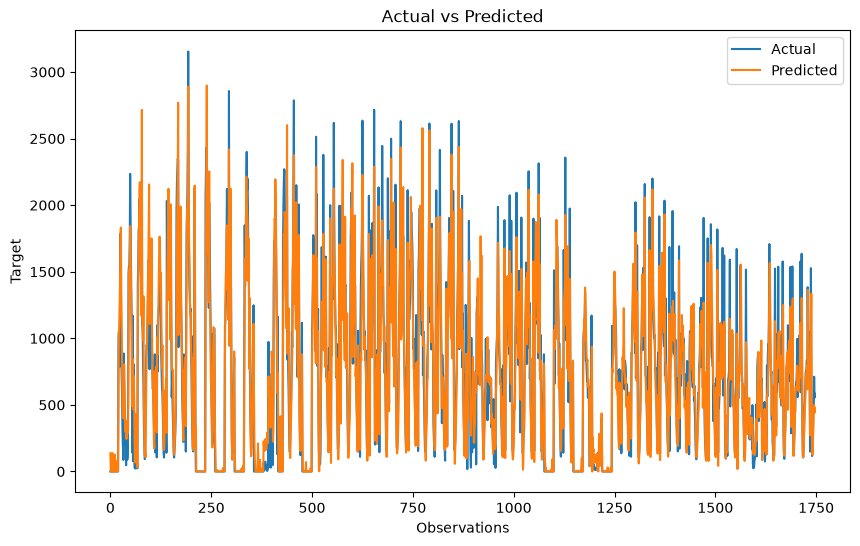

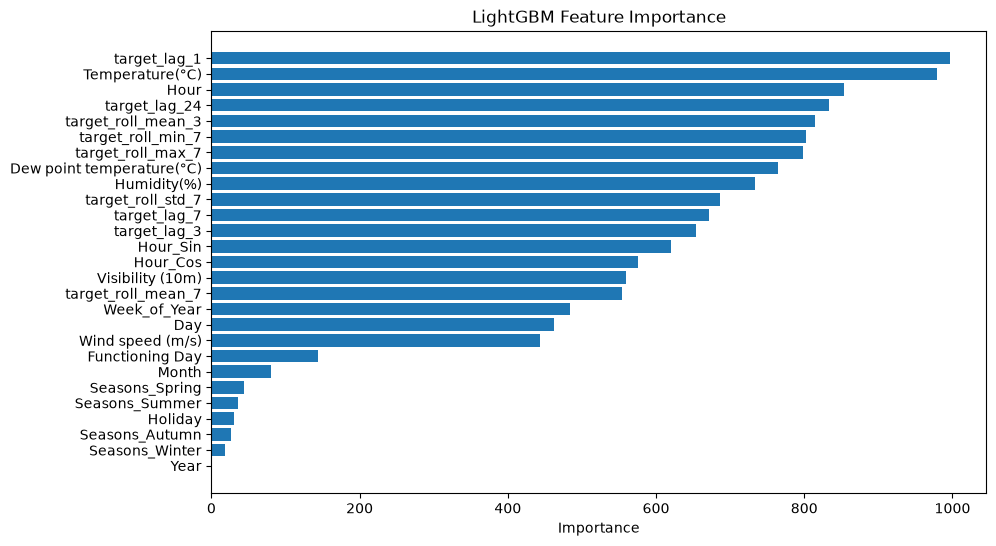

MAE: 137.43 / RMSE: 201.77 / R²: 0.8916


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.lightgbm

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

with mlflow.start_run(run_name="LightGBM_final"):

    final_model = LGBMRegressor(
        **study.best_params,
         random_state=42,
         verbose=-1,
         objective="regression"
        )

    # Training
    final_model.fit(X_train, y_train)

    # Prediction
    y_pred = final_model.predict(X_test)

    # Avoid negative predictions
    y_pred = np.maximum(y_pred, 0)

    # Evaluation
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Actual vs predicted plot
    plt.figure(figsize=(10, 6))
    plt.plot(y_test.values, label="Actual")
    plt.plot(y_pred, label="Predicted")
    plt.legend()
    plt.title("Actual vs Predicted")
    plt.xlabel("Observations")
    plt.ylabel("Target")
    plt.savefig("actual_vs_prediction.png", bbox_inches="tight")
    plt.show()

    # Feature importance
    importance = final_model.feature_importances_
    importance_df = pd.DataFrame({ "Feature": X_train.columns, "Importance": importance})
    importance_df = importance_df.sort_values("Importance", ascending=True)

    plt.figure(figsize=(10, 6))
    plt.barh(importance_df["Feature"], importance_df["Importance"])
    plt.title("LightGBM Feature Importance")
    plt.xlabel("Importance")
    plt.savefig("feature_importance.png", bbox_inches="tight")
    plt.show()

    importance_df.to_csv("feature_importance.csv", index=False)

    # MLflow Logging

    mlflow.log_param("final_model", "LightGBM")
    mlflow.log_param("target_transformation", "None")
    mlflow.log_params(study.best_params)

    mlflow.log_metric("MAE", mae)
    mlflow.log_metric("RMSE", rmse)
    mlflow.log_metric("R2", r2)

    mlflow.log_artifact("actual_vs_prediction.png")
    mlflow.log_artifact("feature_importance.png")
    mlflow.log_artifact("feature_importance.csv")

    mlflow.lightgbm.log_model(final_model, name="final_model")

    print("MAE:", round(mae, 2), "/ RMSE:", round(rmse, 2), "/ R²:", round(r2, 4))

In [39]:
import joblib

# saves the model locally
joblib.dump(final_model, "lightgbm_final_model.pkl")

['lightgbm_final_model.pkl']